<a href="https://colab.research.google.com/github/Meerjashaik/ML-LAB-WORK/blob/main/ML_Lab(Random_Forest).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Random Forest In Machine Learning**



In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [23]:
iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)

df['target'] = y

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [26]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [27]:
y_pred = model.predict(X_test)

print("Actual Values:", y_test)
print("Predicted Values:", y_pred)

Actual Values: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]
Predicted Values: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


In [28]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy * 100, "%")

Accuracy: 100.0 %


Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


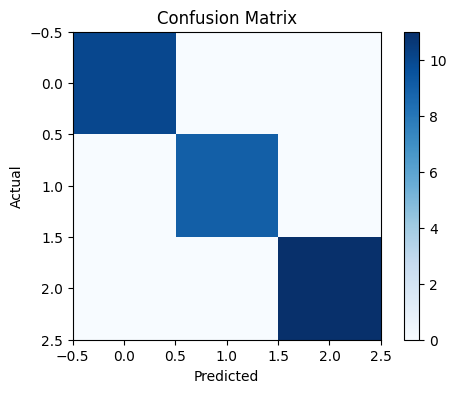

In [29]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))

plt.imshow(cm, cmap='Blues')

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.colorbar()
plt.show()

In [30]:
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



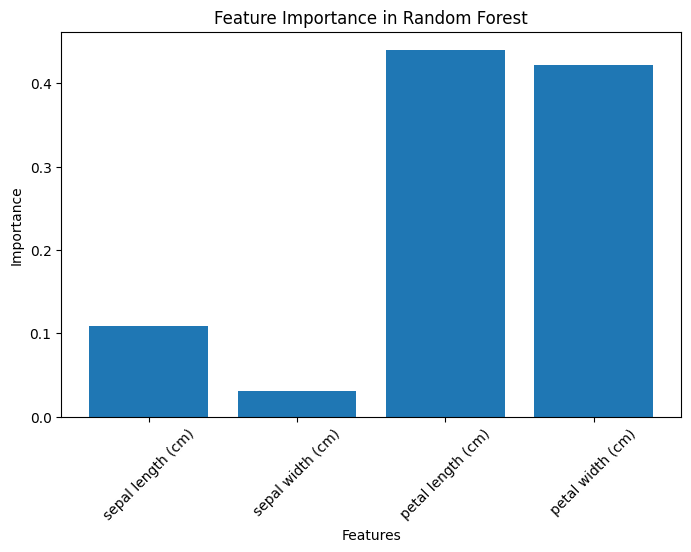

In [31]:
importance = model.feature_importances_

features = iris.feature_names

plt.figure(figsize=(8, 5))

plt.bar(features, importance)

plt.title("Feature Importance in Random Forest")
plt.xlabel("Features")
plt.ylabel("Importance")

plt.xticks(rotation=45)

plt.show()

In [32]:
model = RandomForestClassifier(
    n_estimators=50,
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

print("Accuracy:", model.score(X_test, y_test))

Accuracy: 1.0


# **Questions And Answers**

### Q1. What is Random Forest in Machine Learning
Ans: Random Forest is an ensemble machine learning algorithm that combines the predictions of multiple individual decision trees to generate a single, more accurate, and stable output

### Q2. Why and when we use Random forest
Ans:

###For Why:
 **Reduces Overfitting**: A single decision tree often memorizes the training noise, leading to high variance. Random Forest uses bagging (bootstrap aggregating) and random feature selection so that individual errors cancel out, creating a more stable model.

 **High Accuracy**: By combining many "weak learners" (individual trees), it generally achieves higher accuracy and better generalization on unseen data than a single tree.

 **Handles High-Dimensional Data**: It performs well on datasets with a large number of features and data points without needing aggressive feature reduction.

###For When:
**Tabular and Structured Data**: It is one of the strongest "out-of-the-box" algorithms for spreadsheets, SQL tables, and structured datasets (e.g., customer churn, house price prediction, or financial scoring).

**Classification & Regression Tasks**: Use it when you need to predict discrete categories (e.g., spam vs. not spam, disease diagnosis) or continuous values (e.g., sales numbers, temperature).

**Quick Baseline Model**: When you want a reliable, high-accuracy benchmark model quickly without spending weeks tuning deep neural networks or complex pipelines.

### Q3. Working of Random Forest

Ans:


**1. Bootstrapping (Data Sampling)**

The algorithm does not train every tree on the exact same dataset. Instead, it creates multiple subsets of the original data using a method called bootstrapping.
• If your dataset has \(N\) rows, the algorithm randomly selects \(N\) rows with replacement (meaning the same row can be picked more than once) to create a new subset for each tree.

**2. Feature Randomness (Sub-space Sampling)**

In a standard decision tree, the algorithm looks at every single feature (column) to decide the best way to split a node. Random Forest introduces a twist:
• When splitting a node inside a tree, the algorithm randomly selects a subset of features (e.g., if you have 20 features, it might only look at 4 at a time).
• It then chooses the best feature out of that random subset to make the split. This ensures that the trees in the forest are highly diverse and un-correlated.

**3. Building Individual Trees**

Steps 1 and 2 are repeated until hundreds of independent, deep decision trees are trained. Because they are trained on different data subsets and different feature subsets, every tree in the forest looks slightly different.

**4. Aggregating the Results (The Final Vote)**

When a new data point needs to be predicted, it is passed through every single tree in the forest. Each tree outputs its own prediction. The algorithm then aggregates these predictions:
• For Classification (Predicting a category): It uses Majority Voting. If 70 trees predict "Class A" and 30 trees predict "Class B", the final model output is "Class A".
• For Regression (Predicting a number): It takes the Average. If you are predicting house prices, the model averages the prices predicted by all 100 trees.

### Q4. Applications of Random Forest

Ans:

**Banking & Finance**: Used extensively for credit scoring (evaluating loan applicant risk), fraud detection in real-time transactions, and predicting stock market trends.

**Healthcare & Medicine**: Applied to predict patient outcomes (e.g., surgical readmission risk), identify genetic markers for diseases, and analyze medical diagnostics.

**E-Commerce & Retail**: Powers recommendation engines (like those on Amazon), customer segmentation for personalized marketing, and customer churn prediction.

**Manufacturing**: Used for predictive maintenance by analyzing sensor data to detect anomalies and flag machinery breakdowns before they happen.

**Environmental Science**: Employed to analyze satellite imagery, predict climate patterns, map biodiversity, and monitor deforestation trends.